# Лабораторная работа № 6. Кодирование и масштабирование

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Привести очищенную выборку Glass к виду, пригодному для алгоритмов машинного обучения: закодировать категориальные переменные и масштабировать числовые признаки.

## 1. Теоретическая часть

**1. Почему кодирование и масштабирование обязательны?** Алгоритмы ML оперируют числами: категории нужно превратить в числа, иначе модель не обучится. Масштабирование приводит признаки к сопоставимым диапазонам; без него признаки с большими числовыми значениями (Si ≈ 72) подавляют признаки с малыми (RI ≈ 1.52, Ba ≈ 0.1) в методах на основе расстояний и градиентов.

**2. Числовые и категориальные признаки.** Числовые (количественные) — имеют арифметический смысл, их подготавливают масштабированием/нормализацией. Категориальные — набор меток; их сначала кодируют в числа (Label/One-Hot/Ordinal) и не масштабируют как числа.

**3. LabelEncoder и OneHotEncoder.** LabelEncoder присваивает каждой категории целое число (0, 1, 2…) — подходит для целевой переменной и порядковых признаков, но вводит ложный порядок для номинальных. OneHotEncoder создаёт отдельный бинарный столбец на каждую категорию — подходит для номинальных признаков без порядка, но увеличивает число признаков.

**4. Чувствительность к масштабу.** Методы, использующие расстояния (kNN, SVM, кластеризация), градиентный спуск и регуляризацию (линейные модели, нейросети), чувствительны к абсолютным величинам признаков: признак с большим диапазоном даёт больший вклад. Деревья масштаб не учитывают.

**5. StandardScaler и MinMaxScaler.** StandardScaler: (x − μ)/σ — среднее 0, std 1, форма распределения сохраняется, диапазон не ограничен, менее чувствителен к выбросам по влиянию на диапазон. MinMaxScaler: (x − min)/(max − min) — приводит к [0, 1], но сильно зависит от выбросов; форма распределения тоже сохраняется (линейное преобразование).

## 2. Практическая часть

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

# ---------- сквозной пайплайн подготовки данных (ЛР 5-7) ----------
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def clean_glass(d):
    """ЛР 5: пропуски, допустимые пределы, дубликаты."""
    d = d.copy()
    d = d.dropna()
    ok = d[["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]].apply(lambda s: s.between(0, 100)).all(axis=1)
    ok &= d["RI"].between(1.3, 1.7)
    return d[ok].drop_duplicates().reset_index(drop=True)

def scale_glass(d):
    """ЛР 6: стандартизация признаков (целевая Type не масштабируется)."""
    s = d.copy()
    s[FEATURES] = StandardScaler().fit_transform(d[FEATURES])
    return s

def select_glass(s):
    """ЛР 7: три метода отбора (фильтр, обёртка, встроенный) + голосование >= 2."""
    X, y = s[FEATURES], s["Type"]
    f1 = set(X.columns[SelectKBest(f_classif, k=6).fit(X, y).get_support()])
    f2 = set(X.columns[RFE(LogisticRegression(max_iter=2000), n_features_to_select=6).fit(X, y).get_support()])
    f3 = set(X.columns[SelectFromModel(RandomForestClassifier(n_estimators=300, random_state=42), threshold="median").fit(X, y).get_support()])
    votes = {f: (f in f1) + (f in f2) + (f in f3) for f in FEATURES}
    keep = [f for f in FEATURES if votes[f] >= 2]
    return s[keep + ["Type"]], keep


clean = clean_glass(df)
print('Очищенная выборка:', clean.shape)

Очищенная выборка: (213, 10)


### 2.1. Базовый уровень

In [ ]:
# Категориальные признаки. Среди признаков категориальных нет; категориальная по смыслу переменная - целевая Type (сорт стекла).
print("Размерность до кодирования:", clean.shape)
display(clean.dtypes.to_frame("dtype").T)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
clean["Type_enc"] = le.fit_transform(clean["Type"])          # метки 1,2,3,5,6,7 -> 0..5 (без «дыры» на месте сорта 4)
print("Размерность после кодирования:", clean.shape)
print("Соответствие кодов:", {int(k): int(v) for k, v in zip(le.classes_, le.transform(le.classes_))})
display(clean[["Type", "Type_enc"]].drop_duplicates().sort_values("Type"))

Размерность до кодирования: (213, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


Размерность после кодирования: (213, 11)
Соответствие кодов: {1: 0, 2: 1, 3: 2, 5: 3, 6: 4, 7: 5}


,Type,Type_enc
0,1,0
69,2,1
145,3,2
162,5,3
175,6,4
184,7,5


**Ответ.** Для целевой переменной использован **LabelEncoder**: у неё нет роли «признака», порядок не используется моделью-классификатором, а нужны компактные индексы классов 0…5 (в данных нет сорта 4, и LabelEncoder убирает «пропуск» в нумерации). Структура данных изменилась на один столбец (`Type_enc`).

In [ ]:
# Числовые признаки и масштабирование StandardScaler
from sklearn.preprocessing import StandardScaler, MinMaxScaler
num = FEATURES
before = clean[num].describe().T[["mean", "std", "min", "max"]]
Xs = pd.DataFrame(StandardScaler().fit_transform(clean[num]), columns=num)
after = Xs.describe().T[["mean", "std", "min", "max"]]
display(pd.concat({"до": before, "после StandardScaler": after}, axis=1).round(3))
print("Диапазон до: от %.2f до %.2f; после: от %.2f до %.2f" % (clean[num].min().min(), clean[num].max().max(), Xs.min().min(), Xs.max().max()))

до                        после StandardScaler                     
      mean    std     min     max                 mean    std    min    max
RI   1.518  0.003   1.511   1.534                 -0.0  1.002 -2.379  5.150
Na  13.404  0.817  10.730  17.380                 -0.0  1.002 -3.282  4.880
Mg   2.679  1.444   0.000   4.490                  0.0  1.002 -1.860  1.257
Al   1.449  0.496   0.290   3.500                 -0.0  1.002 -2.344  4.144
Si  72.655  0.774  69.810  75.410                  0.0  1.002 -3.684  3.568
K    0.499  0.653   0.000   6.210                  0.0  1.002 -0.766  8.764
Ca   8.954  1.426   5.430  16.190                 -0.0  1.002 -2.477  5.087
Ba   0.176  0.498   0.000   3.150                 -0.0  1.002 -0.354  5.983
Fe   0.057  0.098   0.000   0.510                 -0.0  1.002 -0.588  4.650

Диапазон до: от 0.00 до 75.41; после: от -3.68 до 8.76


**Ответ.** До масштабирования диапазоны различались на два порядка (RI ≈ 0.02 против Si ≈ 5.6). После стандартизации у всех признаков среднее ≈ 0 и std = 1 (диапазон примерно от −3.7 до +8.8; максимум у K из-за выбросов). Это важно для kNN, логистической регрессии, PCA и отбора по дисперсии, иначе признак Si «заглушит» остальные.

In [ ]:
scaled = scale_glass(clean)
assert scaled[FEATURES].isna().sum().sum() == 0
print("Условия уровня 1: все признаки числовые:", all(np.issubdtype(t, np.number) for t in scaled.dtypes), "| NaN:", int(scaled.isna().sum().sum()))
display(scaled.head())

Условия уровня 1: все признаки числовые: True | NaN: 0


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type,Type_enc
0,0.879840,0.289558,1.257238,-0.706370,-1.133248,-0.673480,-0.143466,-0.353808,-0.588301,1,0
1,-0.243816,0.596403,0.639311,-0.180863,0.097037,-0.028962,-0.790201,-0.353808,-0.588301,1,0
2,-0.716412,0.154546,0.604596,0.182950,0.433746,-0.167073,-0.825349,-0.353808,-0.588301,1,0
3,-0.227291,-0.238216,0.701798,-0.322346,-0.058368,0.109149,-0.516041,-0.353808,-0.588301,1,0
4,-0.306608,-0.164573,0.653197,-0.423405,0.550299,0.078457,-0.621487,-0.353808,-0.588301,1,0


### 2.2. Сравнение методов кодирования и масштабирования

In [ ]:
from sklearn.preprocessing import OneHotEncoder
c2 = clean[["Type"]].copy()
c2["Сорт"] = c2["Type"].map(TYPE_NAMES)
lab_enc = LabelEncoder().fit_transform(c2["Сорт"])
ohe = pd.DataFrame(OneHotEncoder(sparse_output=False).fit_transform(c2[["Сорт"]]), columns=sorted(c2["Сорт"].unique()))
print("LabelEncoder  -> 1 столбец, значения:", sorted(int(v) for v in set(lab_enc)))
print("OneHotEncoder ->", ohe.shape[1], "столбцов (в копии данных):"); display(ohe.head(3).astype(int))
print("Число признаков: было", clean.shape[1] - 1, "(+1 столбец при Label, +%d при One-Hot)" % ohe.shape[1])

LabelEncoder  -> 1 столбец, значения: [0, 1, 2, 3, 4, 5]
OneHotEncoder -> 6 столбцов (в копии данных):


,контейнеры,окна авто (float),окна зданий (float),окна зданий (non-float),посуда,фары
0,0,0,1,0,0,0
1,0,0,1,0,0,0
2,0,0,1,0,0,0


Число признаков: было 10 (+1 столбец при Label, +6 при One-Hot)


**Ответ.** One-Hot предпочтительнее для **номинальных признаков без порядка** (сорт, цвет, город) и для линейных моделей / kNN, чтобы избежать ложной упорядоченности и расстояний; LabelEncoder — для целевой переменной и деревьев. Платой за One-Hot является рост размерности.

,исходные mean,исходные std,Standard mean,Standard std,MinMax min,MinMax max,MinMax mean
RI,1.518,0.003,-0.0,1.002,0.0,1.0,0.316
Na,13.404,0.817,-0.0,1.002,0.0,1.0,0.402
Mg,2.679,1.444,0.0,1.002,0.0,1.0,0.597
Al,1.449,0.496,-0.0,1.002,0.0,1.0,0.361
Si,72.655,0.774,0.0,1.002,0.0,1.0,0.508
K,0.499,0.653,0.0,1.002,0.0,1.0,0.080
Ca,8.954,1.426,-0.0,1.002,0.0,1.0,0.328
Ba,0.176,0.498,-0.0,1.002,0.0,1.0,0.056
Fe,0.057,0.098,-0.0,1.002,0.0,1.0,0.112


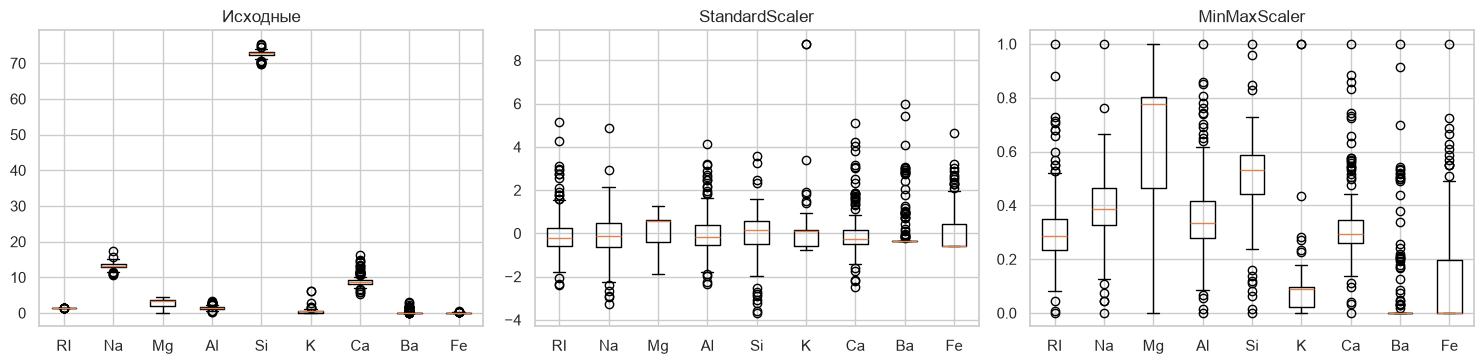

In [ ]:
std = StandardScaler().fit_transform(clean[num]); mm = MinMaxScaler().fit_transform(clean[num])
comp = pd.DataFrame({"исходные mean": clean[num].mean(), "исходные std": clean[num].std(),
                     "Standard mean": std.mean(0), "Standard std": std.std(0, ddof=1),
                     "MinMax min": mm.min(0), "MinMax max": mm.max(0), "MinMax mean": mm.mean(0)}, index=num)
display(comp.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (t, M) in zip(ax, [("Исходные", clean[num].values), ("StandardScaler", std), ("MinMaxScaler", mm)]):
    a.boxplot(M); a.set_xticklabels(num); a.set_title(t)
plt.tight_layout(); plt.show()

**Ответ.** Оба метода — линейные преобразования, поэтому форма распределения (скошенность, бимодальность) не меняется; меняется только положение и масштаб. MinMax даёт строго [0, 1], но сильно зависит от выбросов (у Ba, K, Fe основная масса значений «сжимается» вблизи нуля). StandardScaler устойчивее к такому сжатию и лучше подходит для линейных моделей, PCA и kNN, поэтому в качестве универсального метода выбран он.

### 2.3. Контроль корректности подготовки

In [ ]:
no_scale = clean.drop(columns="Type_enc")                  # версия без масштабирования
with_scale = scale_glass(no_scale)                          # версия с масштабированием
print("Типы:", set(map(str, with_scale.dtypes))); print("NaN:", int(with_scale.isna().sum().sum()), "| размерность:", with_scale.shape)
print("Категориальных (object) значений:", int((with_scale.dtypes == "object").sum()))
rng_ = pd.DataFrame({"без масштаба min": no_scale[FEATURES].min(), "без масштаба max": no_scale[FEATURES].max(),
                     "с масштабом min": with_scale[FEATURES].min(), "с масштабом max": with_scale[FEATURES].max()})
display(rng_.round(3))
display(pd.concat({"без масштабирования": no_scale[FEATURES].describe().loc[["mean", "std"]],
                   "с масштабированием": with_scale[FEATURES].describe().loc[["mean", "std"]]}).round(3))
no_scale.to_csv("glass_unscaled.csv", index=False); with_scale.to_csv("glass_scaled.csv", index=False)
print("Сохранены glass_unscaled.csv и glass_scaled.csv")

Типы: {'int64', 'float64'}
NaN: 0 | размерность: (213, 10)
Категориальных (object) значений: 0


,без масштаба min,без масштаба max,с масштабом min,с масштабом max
RI,1.511,1.534,-2.379,5.150
Na,10.730,17.380,-3.282,4.880
Mg,0.000,4.490,-1.860,1.257
Al,0.290,3.500,-2.344,4.144
Si,69.810,75.410,-3.684,3.568
K,0.000,6.210,-0.766,8.764
Ca,5.430,16.190,-2.477,5.087
Ba,0.000,3.150,-0.354,5.983
Fe,0.000,0.510,-0.588,4.650


RI      Na     Mg     Al      Si      K     Ca     Ba     Fe
без масштабирования mean  1.518  13.404  2.679  1.449  72.655  0.499  8.954  0.176  0.057
                    std   0.003   0.817  1.444  0.496   0.774  0.653  1.426  0.498  0.098
с масштабированием  mean -0.000  -0.000  0.000 -0.000   0.000  0.000 -0.000 -0.000 -0.000
                    std   1.002   1.002  1.002  1.002   1.002  1.002  1.002  1.002  1.002

Сохранены glass_unscaled.csv и glass_scaled.csv


In [ ]:
# наглядное подтверждение риска: kNN без масштабирования и с ним (кросс-валидация)
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
cv = StratifiedKFold(5, shuffle=True, random_state=42)
a0 = cross_val_score(KNeighborsClassifier(5), no_scale[FEATURES], no_scale["Type"], cv=cv).mean()
a1 = cross_val_score(KNeighborsClassifier(5), with_scale[FEATURES], with_scale["Type"], cv=cv).mean()
print(f"kNN accuracy: без масштабирования = {a0:.3f}, с масштабированием = {a1:.3f}")

kNN accuracy: без масштабирования = 0.639, с масштабированием = 0.652


**Ответы.** Риски, если масштабирование пропустить: модели на расстояниях и регуляризации будут определяться признаками с большими числами, сходимость градиентных методов ухудшится, а коэффициенты окажутся несопоставимыми (на этих данных разница kNN невелика — 0.639 против 0.652, так как все оксиды измерены в сопоставимых процентных долях, кроме RI, который имеет крошечный диапазон и без масштабирования почти не влияет на расстояния). Откладывать масштабирование на этап моделирования нельзя, потому что последующий отбор признаков (по дисперсии, корреляции, PCA) уже опирается на масштаб; кроме того, в модельном этапе его необходимо встраивать в `Pipeline`, чтобы параметры (μ, σ) вычислялись только по обучающей части и не было утечки.

### Вывод

Путь данных начинается с очистки: из исходных 214 строк удалён единственный дубликат, получена выборка из 213 образцов без пропусков и недопустимых значений. Затем выполнено кодирование: среди признаков нет категориальных, а категориальная целевая переменная Type закодирована LabelEncoder в индексы 0…5, причём для сравнения показан и вариант One-Hot (6 бинарных столбцов). Далее числовые признаки RI, Na, Mg, Al, Si, K, Ca, Ba, Fe стандартизованы StandardScaler — среднее стало равным 0, а стандартное отклонение — 1. Именно такая последовательность корректна: сначала нужно убрать пропуски и ошибки, иначе они исказят среднее и σ; затем преобразовать категории в числа, чтобы все признаки были числовыми; и только потом масштабировать числовые столбцы, не затрагивая закодированные категории. Мы не масштабировали целевую переменную, чтобы метки классов остались интерпретируемыми. Контроль показал: типы всех признаков числовые, NaN отсутствуют, диапазоны сопоставимы, размерность 213×10. Подготовлены обе версии данных (с масштабированием и без), что подтверждает влияние масштаба на kNN. Формулы масштабирования будут в моделирующих лабораторных вынесены в Pipeline, чтобы избежать утечки информации. Таким образом, данные готовы для отбора признаков, снижения размерности и обучения моделей в следующих работах.